In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

Results to assemble:
- BAGEL2 results
- MAGeCK results
- Gscreend results
- L2FC results
- Specificity
    - cell line wise
    - gene / transcript wise

# Counts

In [22]:
# Get counts
counts = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [23]:
counts

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,865,787,762,652,1532,864,758,669,475,478


# Guide-qc flags

In [17]:
# annotate flagged guides
all_guide_rankings = pd.read_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v2.tsv', 
                                 sep='\t', index_col=0,
                                 header=[0,1]
                                 ).loc[:, 'summary']

In [21]:
all_guide_rankings[['is_working', 'keep_flag']]

,is_working,keep_flag
sgrna,,
RPL10_ENST00000436473_467,True,True
RAN_ENST00000535090_324,True,True
ACTG1_ENST00000573283_1731,True,True
RPL14_ENST00000416518_279,True,True
CCT8_ENST00000286788_1903,True,True
...,...,...
UBE2I_ENST00000397514_282,True,True
SRRM1_ENST00000323848_574,False,False
UBE2D3_ENST00000394803_368,False,False


# BAGEL

In [27]:
filtered = True
time = 'TP5TP6'
name = '_filtered' if filtered else ''
# get data
df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])

bagel_df = df.loc[:, ('alllines', time)].drop(['Recall', 'Precision'], axis=1).rename({'BF': 'Bayesfactor'}, axis=1)
bagel_df.columns = ['Bagel2_' + x for x in bagel_df.columns]
bagel_df


,Bagel2_Bayesfactor,Bagel2_FDR
Gene,,
RAN,4967.985,0.000
MYC,1996.455,0.000
FBL,2887.871,0.000
HNRNPA1,1844.806,0.000
EIF4A1,2449.842,0.000
...,...,...
HOTAIRM1,-406.342,0.135
PCAT1,-343.806,0.135
BIN1,-306.129,0.135


In [236]:
# specificity per line (disfunct)
# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = sdf.loc[:, (slice(None), 'FDR')].var(axis=1).sort_values(ascending=False)
# spec.head(20)

# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = (sdf.loc[:, (slice(None), 'BF')].var(axis=1)/ sdf.loc[:, (slice(None), 'BF')].abs().mean(axis=1)).sort_values(ascending=False)
# spec.head(20)

# MAGeCK

## Guide-wise

In [28]:
# There are three types of MAGeCK output: gene, transcript, and guide wise results

filtered = False
name = '_filtered' if filtered else ''

In [29]:
guide_ranking = pd.read_csv(f'../results/mageck/alllines/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0)
# remove columns that are confusing
guide_ranking = guide_ranking.drop(['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment'], axis=1)
guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

# specificity of guides w.r.t. cell lines
guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/{cell_line}/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0).drop(
    ['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment', 'Gene'], axis=1)
                  for cell_line in cell_line_dict.values()}, axis=1)
spec = guide_rankings.loc[:, (slice(None), 'FDR')].var(axis=1)
guide_ranking['MAGeCK_cell_line_specificity'] = spec

# Rename
guide_ranking = guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

In [30]:
guide_ranking

,Gene,MAGeCK_score,MAGeCK_pval,MAGeCK_FDR,MAGeCK_cell_line_specificity
sgrna,,,,,
RPL10_ENST00000436473_467,RPL10,27.158000,1.996000e-162,1.242500e-158,5.354343e-113
RAN_ENST00000535090_324,RAN,26.162000,7.218600e-151,2.246800e-147,2.377042e-107
ACTG1_ENST00000573283_1731,ACTG1,25.906000,5.726500e-148,1.188200e-144,8.699468e-109
RPL14_ENST00000416518_279,RPL14,25.654000,2.311100e-145,3.596700e-142,1.095423e-105
CCT8_ENST00000286788_1903,CCT8,25.436000,1.019500e-142,1.269300e-139,3.374829e-104
...,...,...,...,...,...
UBE2I_ENST00000397514_282,UBE2I,0.007003,9.944100e-01,9.950500e-01,2.942749e-01
SRRM1_ENST00000323848_574,SRRM1,0.005092,9.959400e-01,9.964200e-01,2.679215e-01
UBE2D3_ENST00000394803_368,UBE2D3,0.002355,9.981200e-01,9.984400e-01,3.231938e-01


## Gene-wise

In [31]:
filtered = True
time = 'TP5TP6'
name = '_filtered' if filtered else ''

gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

In [32]:
df = gene_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
# Cleanup
samples = df.columns.get_level_values(0)
df.columns = df.columns.droplevel(1)
level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
level_2 = samples.str.split('-').str[1]
df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
df.index = df.index.droplevel(1)

In [33]:
df.head()

H1975                                                    H1299  \
                  01                                                       01   
               score   p-value       fdr rank goodsgrna     lfc         score   
id                                                                              
RAN     1.488200e-10  0.000005  0.000036    1        19 -4.9633  1.773800e-12   
FBL     5.304500e-09  0.000005  0.000036    2        12 -6.6671  8.375200e-11   
TMSB4X  9.309300e-08  0.000005  0.000036    3         7 -3.6477  5.900900e-06   
SNHG16  3.598900e-07  0.000005  0.000036    4        10 -3.3369  1.324400e-06   
EIF4A1  7.761900e-07  0.000005  0.000036    5         7 -4.4816  4.233200e-06   

                                ...                                   \
                                ...        03                          
         p-value      fdr rank  ...       fdr rank goodsgrna     lfc   
id                              ...                                    
RAN     0.000005  0.00007    1  ...  0.000049    1        18 -2.3745   
FBL     0.000005  0.00007    2  ...  0.000049   40        10 -1.2269   
TMSB4X  0.000005  0.00007   10  ...  0.000049    5         7 -2.1184   
SNHG16  0.000005  0.00007    5  ...  0.000049    2        10 -2.1641   
EIF4A1  0.000005  0.00007    8  ...  0.000049    4         7 -3.2344   

                A549                                             
                  03                                             
               score   p-value       fdr rank goodsgrna     lfc  
id                                                               
RAN     2.400100e-09  0.000005  0.000053    1        19 -2.3943  
FBL     1.747000e-04  0.000015  0.000134   25        10 -1.2671  
TMSB4X  7.073000e-06  0.000005  0.000053    6         7 -2.2624  
SNHG16  2.910400e-07  0.000005  0.000053    2        10 -2.1123  
EIF4A1  1.290500e-06  0.000005  0.000053    4         7 -3.9778  

[5 rows x 54 columns]

In [34]:
# Reduction
sdf = df.median(level=(0,2), axis=1)  # median across replicates, minimum across cell lines
sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
# sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
mdf.columns = ['MAGeCK_' + x for x in mdf.columns]
mageck_gene = mdf.copy()

In [384]:
mageck_gene

,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,
FBL,0.015816,0.000005,0.000007,-5.03160
TMSB4X,0.000978,0.000005,0.000007,-3.16050
RAN,0.000243,0.000005,0.000007,-5.33550
RHEB,0.000601,0.000005,0.000007,-4.35710
EIF4A1,0.000487,0.000005,0.000007,-5.16110
...,...,...,...,...
CIC,0.425300,0.000005,0.000007,-1.05050
APTR,0.976190,0.305940,0.352176,-0.37924
LINC01089,0.996940,0.554920,0.581181,-0.14408


## Transcript-wise

In [36]:
transcript_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
transcript_ranking = transcript_ranking.reset_index().set_index(['id', 'num'])
transcript_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in transcript_ranking.columns],
    [x.split('|')[1] for x in transcript_ranking.columns],
    [x.split('|')[2] for x in transcript_ranking.columns]
])

In [37]:
df = transcript_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
# Cleanup
samples = df.columns.get_level_values(0)
df.columns = df.columns.droplevel(1)
level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
level_2 = samples.str.split('-').str[1]
df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
df.index = df.index.droplevel(1)

In [38]:
# Reduction
sdf = df.median(level=(0,2), axis=1)  # median across replicates, minimum across cell lines
sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
# sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
mdf.columns = ['MAGeCK_' + x for x in mdf.columns]
mageck_transcript = mdf.copy()

# Gscreend (Fernanda)

## gene-wise

In [39]:
# aggregate data
filtered = True  # False not working with this, has different format
key = 'Gscreend_results_cleaned_data_Sym_0' if filtered else 'gscreend_results_Sym101_0'

dat = []
for i in [1,2,3]:
    gsc = pd.read_excel(f'../resources/fernanda_gscreend/{key}{i}.xlsx', index_col=0)
    level_0 = gsc.columns.str.split('_').str[-2].astype(int).map(cell_line_dict)
    level_1 = gsc.columns.str.split('_').str[-1]
    level_2 = gsc.columns.str.split('_').str[0]
    gsc.columns = pd.MultiIndex.from_arrays([level_0, level_1, level_2])
    dat.append(gsc)
gsc_df = pd.concat(dat, axis=1)

# Take best value across time points, used across cell lines to derive cell line specificity
gsc_min_df = gsc_df.min(axis=1, level=(0, 2))
cell_line_specificity = gsc_min_df.loc[:, (slice(None), 'FDR')].var(axis=1) * 3

# Take the smallest value across all cell lines and time (if it was a hit in one, it's still a hit)
gsc_min2_df = gsc_df.min(axis=1, level=(2))
gsc_min2_df['cell_line_specificity'] = cell_line_specificity
# add _gscreend suffix to columns
gsc_min2_df.columns = gsc_min2_df.columns.map(lambda x: f'Gscreend_{x}')

In [40]:
gsc_min2_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
AATBC,1.00000,1.000000,0.224941,0.000000
ACTA2-AS1,1.00000,1.000000,0.181879,0.000000
ACTB,0.00000,0.000000,-5.811671,0.000000
ACTG1,0.00000,0.000000,-5.650976,0.000000
ADAR,0.13125,0.011297,-2.398691,0.754727


In [41]:
gsc_min2_df.sort_values('Gscreend_cell_line_specificity', ascending=False).head(20)

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
MED28,0.000000,0.000000,-3.683742,1.000000
TMSB4X,0.000000,0.000000,-3.961820,1.000000
SNRPD1,0.000000,0.000000,-3.350189,1.000000
KRT18,0.000000,0.000000,-2.546232,1.000000
KRT7,0.000000,0.000000,-2.992054,1.000000
NUP133,0.000000,0.000000,-2.046877,1.000000
HNRNPM,0.000000,0.000000,-2.939015,0.984344
MT2A,0.003571,0.000182,-2.767969,0.982942
ATP5MF,0.008721,0.000547,-1.172383,0.982634


## Transcript-wise (disfunct)

In [51]:
# aggregate data
filtered = True  # False not working with this, has different format
key = 'Gscreend_results_cleaned_data_transcript_level_Sym_0' if filtered else 'gnscreend_results_Sym101_0{i}_Transcript_level'

dat = []
for i in [1,2,3]:
    gsc = pd.read_excel(f'../resources/fernanda_gscreend/{key}{i}.xlsx', index_col=0)
    level_0 = gsc.columns.str.split('_').str[-2].astype(int).map(cell_line_dict)
    level_1 = gsc.columns.str.split('_').str[-1]
    level_2 = gsc.columns.str.split('_').str[0]
    gsc.columns = pd.MultiIndex.from_arrays([level_0, level_1, level_2])
    dat.append(gsc)
gsc_df_trans = pd.concat(dat, axis=1)

# Take best value across time points, used across cell lines to derive cell line specificity
gsc_min_df_trans = gsc_df_trans.min(axis=1, level=(0, 2))
cell_line_specificity = gsc_min_df_trans.loc[:, (slice(None), 'FDR')].var(axis=1) * 3

# Take the smallest value across all cell lines and time (if it was a hit in one, it's still a hit)
gsc_min2_df_trans = gsc_df_trans.min(axis=1, level=(2))
gsc_min2_df_trans['cell_line_specificity'] = cell_line_specificity
# add _gscreend suffix to columns
gsc_min2_df_trans.columns = gsc_min2_df_trans.columns.map(lambda x: f'Gscreend_{x}')

In [61]:
counts.loc[gsc_df_trans.index]

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
Gene,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_3822,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA3683:3800-3822,AGCCACTCTGACTTTGTGACCAG,3822.0,0.799008,Gene_Body,4598.0,...,1299,1399,1262,1365,1330,1180,1270,1540,1127,1411
AATBC_ENST00000400385_827,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0805:805-827,AAGAGACCTGGAGAAGCAGCTTC,827.0,0.707384,Gene_Body,4598.0,...,1254,1695,1438,1387,1270,1286,1258,1648,1371,1398
ACTA2-AS1_ENST00000437930_943,ENST00000437930,ENSG00000180139,ACTA2-AS1,lncRNA,crRNA0901:921-943,CAAACAGGAATACGATGAAGCCG,943.0,0.861795,Gene_Body,2450.0,...,1043,1195,1039,1101,1108,933,948,1216,819,900
ACTB_ENST00000331789_1318,ENST00000331789,ENSG00000075624,ACTB,protein_coding,crRNA1279,GCAACTAAGTCATAGTCCGCCTA,1318.0,0.998200,CDS,NaN,...,395,329,310,226,1047,483,357,307,259,275
ACTB_ENST00000331789_1320,ENST00000331789,ENSG00000075624,ACTB,protein_coding,crRNA1281,ACGCAACTAAGTCATAGTCCGCC,1320.0,0.996500,CDS,NaN,...,185,143,120,50,854,240,196,114,63,57
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2_ENST00000254821_255,ENST00000254821,ENSG00000132485,ZRANB2,protein_coding,crRNA0213:233-255,GCCCAATTCACATTGCTGCAAGT,255.0,1.230637,CDS,2821.0,...,507,566,546,456,682,477,500,475,345,444
ZRANB2_ENST00000370920_165,ENST00000370920,ENSG00000132485,ZRANB2,protein_coding,crRNA0143:143-165,AACTAGCCAGGAATTCAGCTTGT,165.0,1.001390,UTR5,2816.0,...,1732,2165,1765,1895,1963,1621,1827,2278,1739,1775
ZRANB2_ENST00000370920_2493,ENST00000370920,ENSG00000132485,ZRANB2,protein_coding,crRNA2236:2471-2493,CCCATAACAAAAAGCCCCCAAGC,2493.0,1.358361,UTR3,2816.0,...,1121,1339,1106,1051,1303,1036,991,1220,974,1060


In [54]:
gsc

A549                                \
                                    TP1                           TP2   
                                    FDR    pvalue       LFC       FDR   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  1.000000  0.211218  1.000000   
AATBC_ENST00000400385_827      1.000000  1.000000  0.310604  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  1.000000  0.181879  1.000000   
ACTB_ENST00000331789_1318      0.040107  0.002761 -0.431251  0.045151   
ACTB_ENST00000331789_1320      0.013542  0.000619 -0.594553  0.003623   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255     1.000000  1.000000  0.052782  1.000000   
ZRANB2_ENST00000370920_165     1.000000  1.000000  0.119084  1.000000   
ZRANB2_ENST00000370920_2493    1.000000  1.000000  0.276867  1.000000   
ZRANB2_ENST00000370920_541     1.000000  1.000000  0.130714  1.000000   
ZSWIM3_ENST00000255152_32      1.000000  1.000000 -0.114863  1.000000   

                                                                       \
                                                        TP3             
                                 pvalue       LFC       FDR    pvalue   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  0.458820  1.000000  1.000000   
AATBC_ENST00000400385_827      1.000000  0.608260  1.000000  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  0.334385  1.000000  1.000000   
ACTB_ENST00000331789_1318      0.005141 -1.124234  0.046094  0.005569   
ACTB_ENST00000331789_1320      0.000095 -1.857138  0.004464  0.000143   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255     1.000000  0.039987  1.000000  1.000000   
ZRANB2_ENST00000370920_165     1.000000  0.309552  1.000000  1.000000   
ZRANB2_ENST00000370920_2493    1.000000  0.304873  1.000000  1.000000   
ZRANB2_ENST00000370920_541     1.000000  0.000620  1.000000  1.000000   
ZSWIM3_ENST00000255152_32      1.000000  0.062392  1.000000  1.000000   

                                                                       \
                                              TP4                       
                                    LFC       FDR    pvalue       LFC   
Gene                                                                    
AATBC_ENST00000400385_3822     0.486565  1.000000  1.000000  0.570228   
AATBC_ENST00000400385_827      0.597440  1.000000  1.000000  0.832474   
ACTA2-AS1_ENST00000437930_943  0.341468  1.000000  1.000000  0.466112   
ACTB_ENST00000331789_1318     -1.538425  0.612367  0.087681 -1.863502   
ACTB_ENST00000331789_1320     -2.429188  0.001786  0.000048 -2.870997   
...                                 ...       ...       ...       ...   
ZRANB2_ENST00000254821_255    -0.080644  1.000000  1.000000 -0.160646   
ZRANB2_ENST00000370920_165     0.366931  1.000000  1.000000  0.471356   
ZRANB2_ENST00000370920_2493    0.399047  1.000000  1.000000  0.453942   
ZRANB2_ENST00000370920_541    -0.023650  1.000000  1.000000 -0.096491   
ZSWIM3_ENST00000255152_32      0.128821  1.000000  1.000000  0.159714   

                                                                       \
                                    TP5                           TP6   
                                    FDR    pvalue       LFC       FDR   
Gene                                                                    
AATBC_ENST00000400385_3822     1.000000  1.000000  0.539292  1.000000   
AATBC_ENST00000400385_827      1.000000  1.000000  0.859932  1.000000   
ACTA2-AS1_ENST00000437930_943  1.000000  1.000000  0.479884  1.000000   
ACTB_ENST00000331789_1318      0.072439  0.010091 -1.790141  0.677835   
ACTB_ENST00000331789_1320      0.002604  0.000095 -3.246449  0.004310   
...                                 ...       ...       ...       ...   
ZRANB2_ENST000002

In [43]:
gsc_min2_df_trans.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
AATBC_ENST00000400385_3822,1.000000,1.000000,0.060494,0.000000
AATBC_ENST00000400385_827,1.000000,1.000000,0.310604,0.000000
ACTA2-AS1_ENST00000437930_943,1.000000,1.000000,0.181879,0.000000
ACTB_ENST00000331789_1318,0.040107,0.002761,-3.081346,0.907140
ACTB_ENST00000331789_1320,0.000000,0.000000,-6.079155,0.000003


# Merging

In [44]:
# I could remove the LFCs because each method has a different way of calculating it

In [45]:
# Gene-wise
gene_df = pd.merge(gsc_min2_df, mageck_gene, left_index=True, right_index=True, how='outer')
gene_df = pd.merge(gene_df, bagel_df, left_index=True, right_index=True, how='outer')
gene_df.to_csv('../results/merged/gene_results.csv')
gene_df.head(10)

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_Bayesfactor,Bagel2_FDR
AATBC,1.000000,1.000000,0.224941,0.000000,0.982900,0.744970,0.853306,0.076785,-124.940,0.113
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,-41.471,0.000
ACTA2-AS1,1.000000,1.000000,0.181879,0.000000,0.984300,0.728860,0.910502,0.088836,-131.842,0.116
ACTB,0.000000,0.000000,-5.811671,0.000000,0.001057,0.000005,0.000036,-3.855500,1111.133,0.000
ACTG1,0.000000,0.000000,-5.650976,0.000000,0.000782,0.000005,0.000036,-2.905100,1438.638,0.000
ADAMTS9-AS2,NaN,NaN,NaN,NaN,0.909790,0.119110,0.282013,-0.165340,-47.341,0.006
ADAR,0.131250,0.011297,-2.398691,0.754727,0.020125,0.000005,0.000036,-1.930500,456.051,0.000
ADH5,1.000000,1.000000,-0.962940,0.000000,0.333290,0.008219,0.019421,-0.483830,129.337,0.000
AFAP1-AS1,1.000000,1.000000,-0.493904,0.000000,0.994860,0.804470,0.961810,0.005320,-50.128,0.012
ALDOA,0.453869,0.055211,-1.442984,0.298259,0.104840,0.000133,0.000365,-1.398000,291.594,0.000


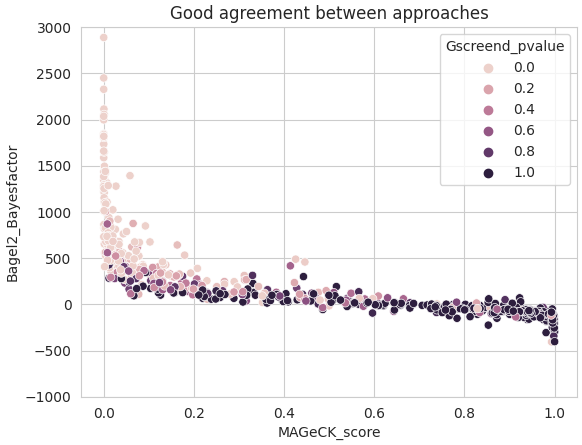

In [46]:
with sns.axes_style('whitegrid'):
    sns.scatterplot(data=gene_df, x='MAGeCK_score', y='Bagel2_Bayesfactor', hue='Gscreend_pvalue')
pl.title('Good agreement between approaches')
pl.ylim(-1000, 3000)
pl.show()

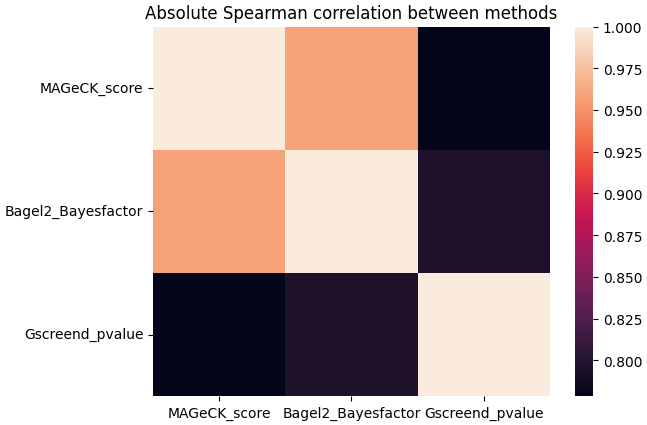

In [47]:
spearman = gene_df[['MAGeCK_score', 'Bagel2_Bayesfactor', 'Gscreend_pvalue']].corr(method='spearman').abs()
sns.heatmap(spearman, annot=False)
pl.title('Absolute Spearman correlation between methods')
pl.show()

In [62]:
# transcript-wise
transcript_df = mageck_transcript.copy()#pd.merge(gsc_min2_df_trans, mageck_transcript, left_index=True, right_index=True, how='outer')
transcript_df.to_csv('../results/merged/transcript_results.csv')

In [63]:
transcript_df

,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,
ENST00000451311,0.000007,0.000005,0.000044,-2.832900
ENST00000493536,0.000001,0.000005,0.000044,-3.336900
ENST00000293831,0.000004,0.000005,0.000044,-4.676400
ENST00000230050,0.000024,0.000005,0.000044,-5.480800
ENST00000245458,0.000006,0.000005,0.000044,-4.306500
...,...,...,...,...
ENST00000317501,0.971250,0.762330,1.000000,0.141390
ENST00000264659,0.995830,0.811350,1.000000,0.115920
ENST00000402312,0.995700,0.934530,1.000000,0.101280


In [64]:
# guide-wise
guide_df = guide_ranking.copy()
guide_df.to_csv('../results/merged/guide_results.csv')

In [65]:
# Multi-sheet excel
with pd.ExcelWriter('../results/merged/merged_results.xlsx') as writer:
    gene_df.to_excel(writer, sheet_name='gene_results')
    transcript_df.to_excel(writer, sheet_name='transcript_results')
    guide_df.to_excel(writer, sheet_name='guide_results')